In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('../data/sunspots.csv', parse_dates=['Month'])

In [3]:
df

,Month,Sunspots
0,1749-01-01,58.0
1,1749-02-01,62.6
2,1749-03-01,70.0
3,1749-04-01,55.7
4,1749-05-01,85.0
...,...,...
2800,1983-07-01,82.2
2801,1983-09-01,50.3
2802,1983-10-01,55.8
2803,1983-11-01,33.3


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2805 entries, 0 to 2804
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Month     2805 non-null   datetime64[ns]
 1   Sunspots  2805 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 44.0 KB


# Проверка частоты дискретизации

In [5]:
print(pd.infer_freq(df['Month']))

None


In [6]:
values, counts = np.unique(np.diff(df['Month']), return_counts=True)
print(values.astype('timedelta64[D]'))
print(counts)

[28 29 30 31 59 60 61 62]
[ 178   53  934 1624    1    3    6    5]


In [7]:
df['diff'] = np.append(np.timedelta64('NaT'), np.diff(df['Month']))

In [8]:
a = [59, 60, 61, 62]
b = [f'{i} days' for i in a]
idx = df[df['diff'].isin(b)].index
idx = idx.append(idx-1)
df.iloc[idx].sort_index()

C:\Users\Denis\AppData\Local\Temp\ipykernel_25272\2841092718.py:3: FutureWarning: The behavior of 'isin' with dtype=timedelta64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  idx = df[df['diff'].isin(b)].index


,Month,Sunspots,diff
210,1766-07-01,3.3,30 days
211,1766-09-01,4.3,62 days
448,1786-06-01,59.0,31 days
449,1786-08-01,89.7,61 days
540,1794-03-01,38.0,28 days
541,1794-05-01,55.7,61 days
801,1816-01-01,26.3,31 days
802,1816-03-01,73.7,60 days
1280,1856-01-01,0.5,31 days
1281,1856-03-01,0.4,60 days


In [9]:
df = df.set_index('Month').asfreq(freq='MS').reset_index()

In [10]:
df = df.drop(columns='diff')

In [11]:
np.unique(np.diff(df['Month'])).astype('timedelta64[D]')

array([28, 29, 30, 31], dtype='timedelta64[D]')

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2820 entries, 0 to 2819
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Month     2820 non-null   datetime64[ns]
 1   Sunspots  2805 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 44.2 KB


# Деление на обучение и тест

In [13]:
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [14]:
train, test = train_test_split(df, test_size=0.2, shuffle=False)

In [15]:
train.tail(5)

,Month,Sunspots
2251,1936-08-01,87.0
2252,1936-09-01,76.0
2253,1936-10-01,89.0
2254,1936-11-01,115.4
2255,1936-12-01,123.4


In [16]:
test.head()

,Month,Sunspots
2256,1937-01-01,132.5
2257,1937-02-01,128.5
2258,1937-03-01,83.9
2259,1937-04-01,109.3
2260,1937-05-01,116.7


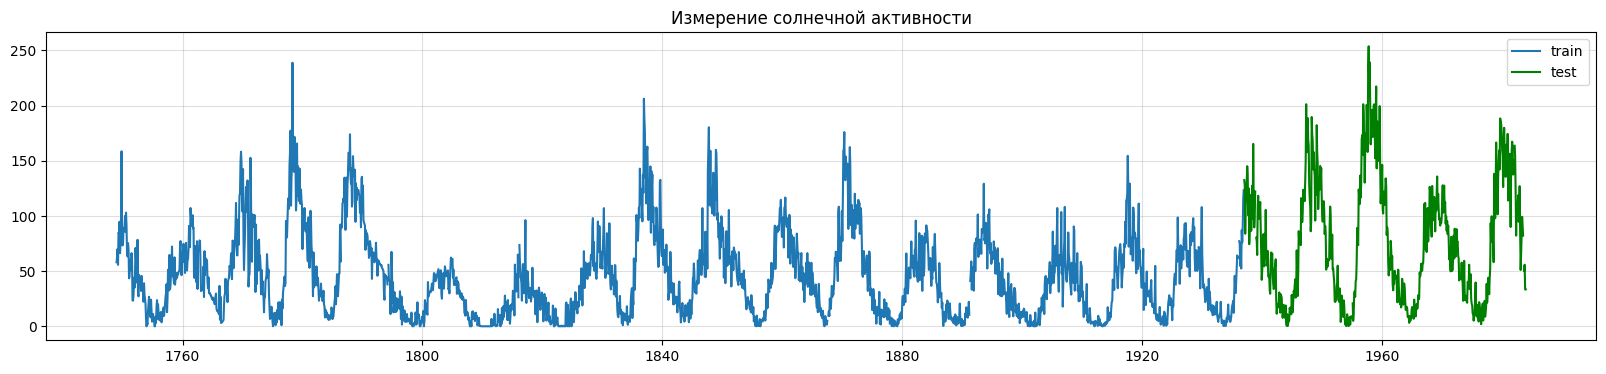

In [17]:
plt.figure(figsize=(20, 4))
plt.plot(train['Month'], train['Sunspots'], label='train')
plt.plot(test['Month'], test['Sunspots'], c='g', label='test')
plt.title('Измерение солнечной активности')
plt.legend()
plt.grid(alpha=0.4)

# Обработка пропущенных значений

In [18]:
df[df['Sunspots'].isna()]

,Month,Sunspots
211,1766-08-01,NaN
450,1786-07-01,NaN
543,1794-04-01,NaN
805,1816-02-01,NaN
1285,1856-02-01,NaN
1307,1857-12-01,NaN
1423,1867-08-01,NaN
1694,1890-03-01,NaN
1707,1891-04-01,NaN
2118,1925-07-01,NaN


In [19]:
nan_idx = df[df['Sunspots'].isna()].index

In [20]:
slice_size = 5
slices = [(idx - slice_size, idx + slice_size) for idx in nan_idx]

In [21]:
slices

[(206, 216),
 (445, 455),
 (538, 548),
 (800, 810),
 (1280, 1290),
 (1302, 1312),
 (1418, 1428),
 (1689, 1699),
 (1702, 1712),
 (2113, 2123),
 (2240, 2250),
 (2274, 2284),
 (2467, 2477),
 (2791, 2801),
 (2810, 2820)]

In [22]:
def draw_slices(df, time_col, target_col, slices):
    n_rows = len(slices)
    fig, ax = plt.subplots(n_rows, 1, figsize=(12, 6*n_rows))

    if n_rows == 1:
        ax = [ax]

    for i in range(n_rows):
        x_slice = df[time_col][slices[i][0]:slices[i][1]].copy()
        y_slice = df[target_col][slices[i][0]:slices[i][1]].copy()
        nan_idx = y_slice[y_slice.isna()].index

        x_slice = x_slice.drop(nan_idx)
        y_slice = y_slice.drop(nan_idx)
        
        ax[i].plot(x_slice, y_slice, marker='o')
        ax[i].set_title(f'Строки: {slices[i][0]}-{slices[i][1]}')

        label = ax[i].get_xticklabels()[slice_size]
        label.set_color('red')
        label.set_weight('bold')

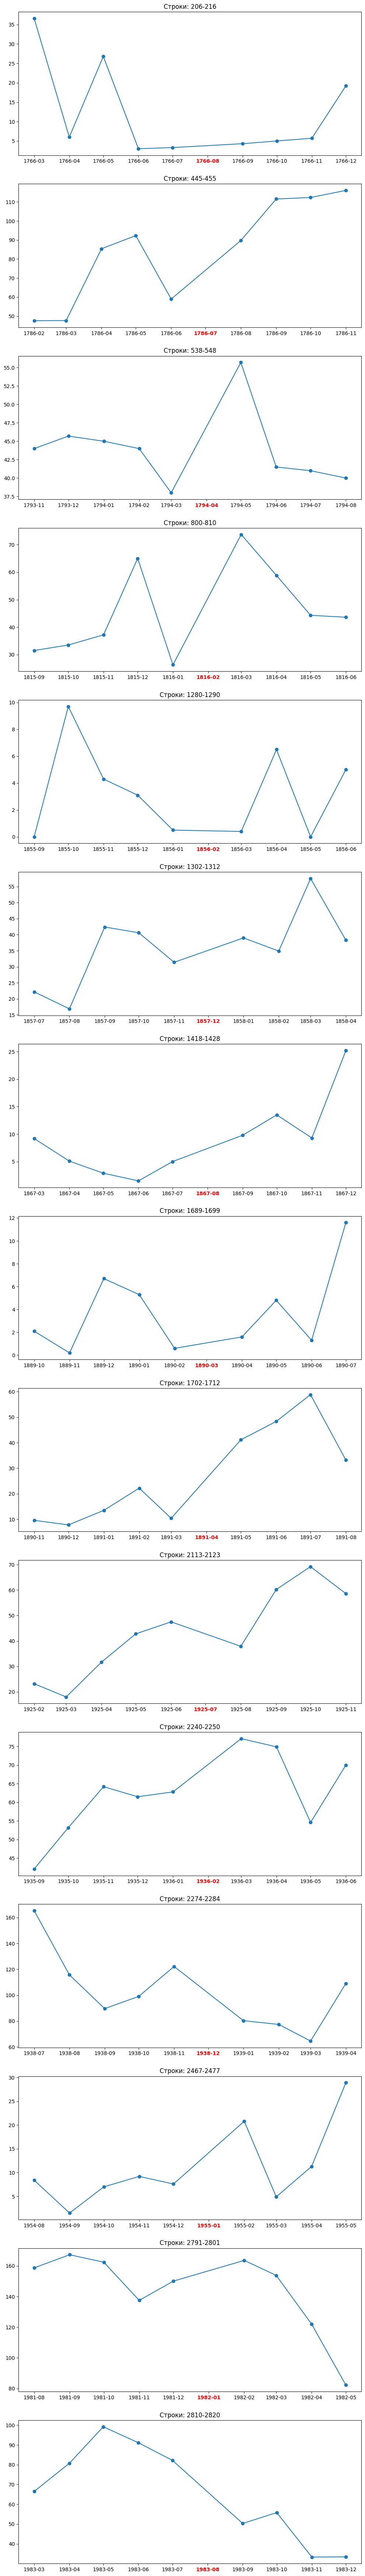

In [23]:
draw_slices(df, 'Month', 'Sunspots', slices)

In [24]:
train['ffill'] = train['Sunspots'].ffill()
test['ffill'] = test['Sunspots'].ffill()
df['ffill'] = pd.concat([train['ffill'], test['ffill']], axis=0)

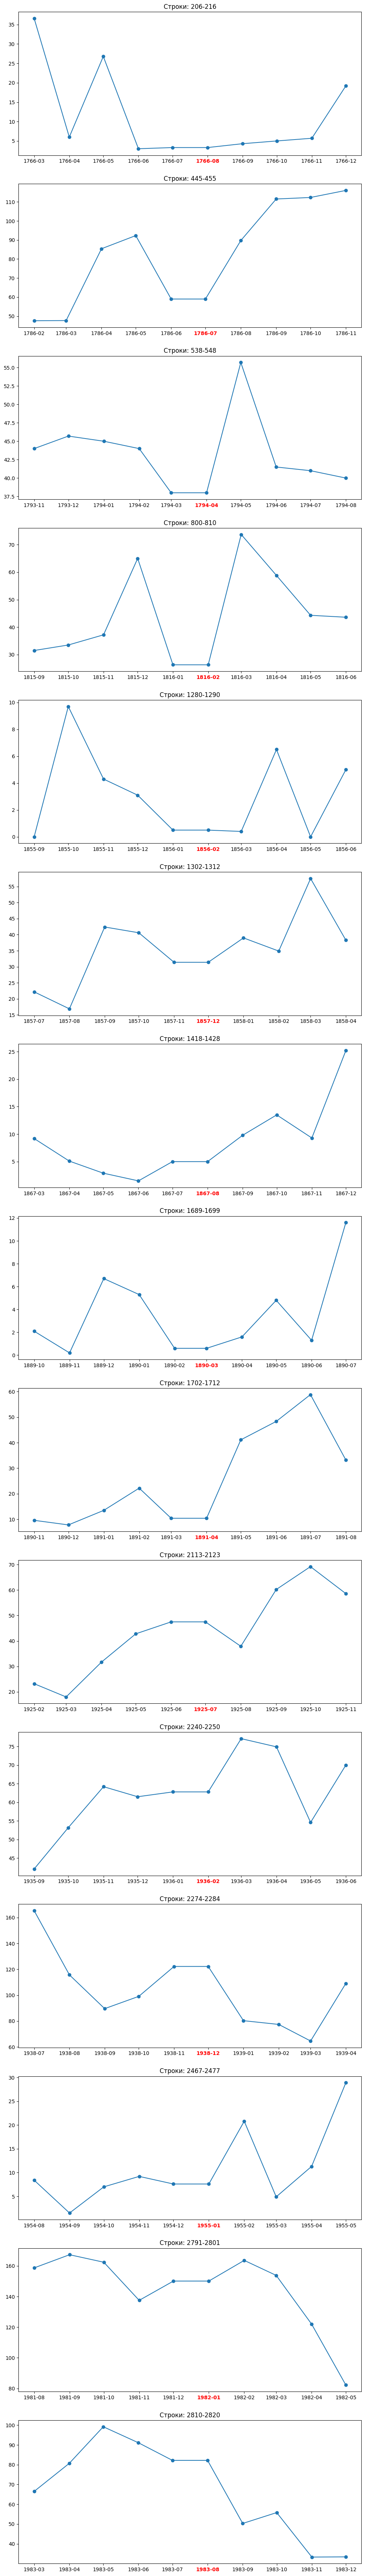

In [25]:
draw_slices(df, 'Month', 'ffill', slices)

In [26]:
train['bfill'] = train['Sunspots'].bfill()
test['bfill'] = test['Sunspots'].bfill()
df['bfill'] = pd.concat([train['bfill'], test['bfill']], axis=0)

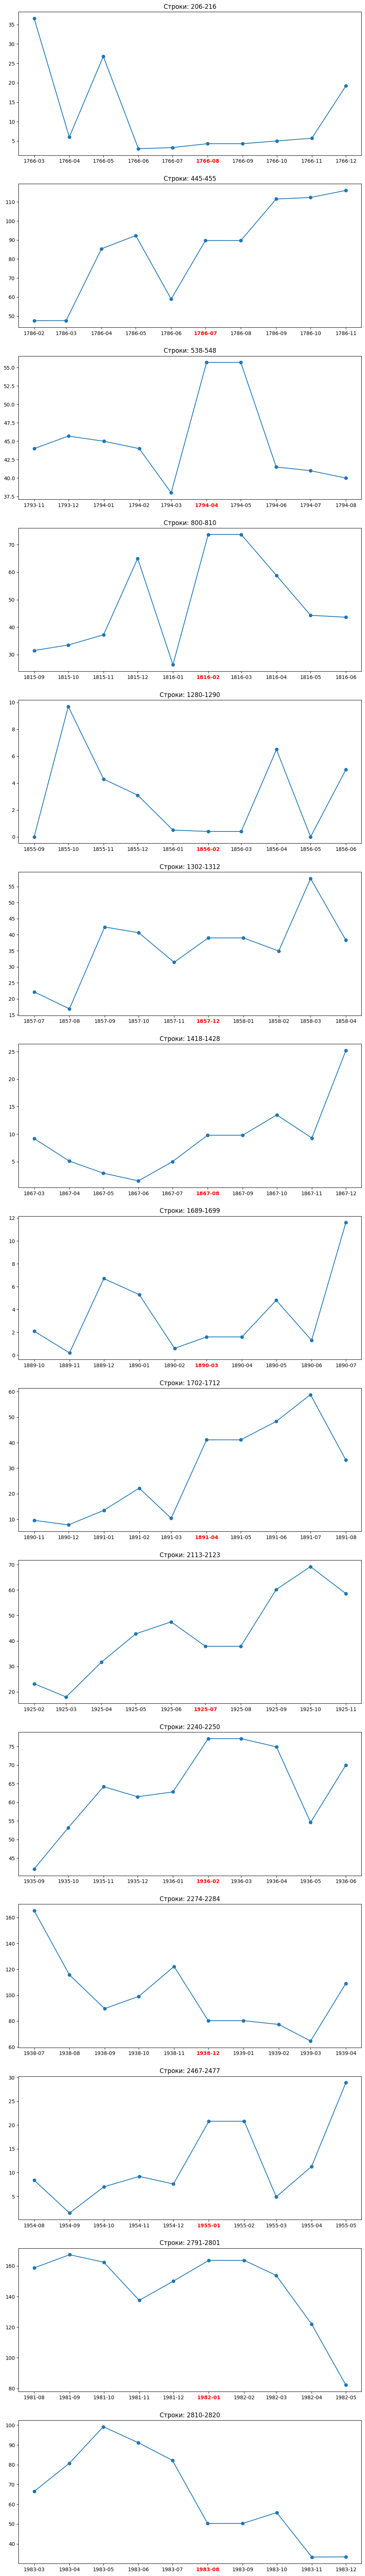

In [27]:
draw_slices(df, 'Month', 'bfill', slices)

In [28]:
train['linear'] = train['Sunspots'].interpolate(method='linear')
test['linear'] = test['Sunspots'].interpolate(method='linear')
df['linear'] = pd.concat([train['linear'], test['linear']], axis=0)

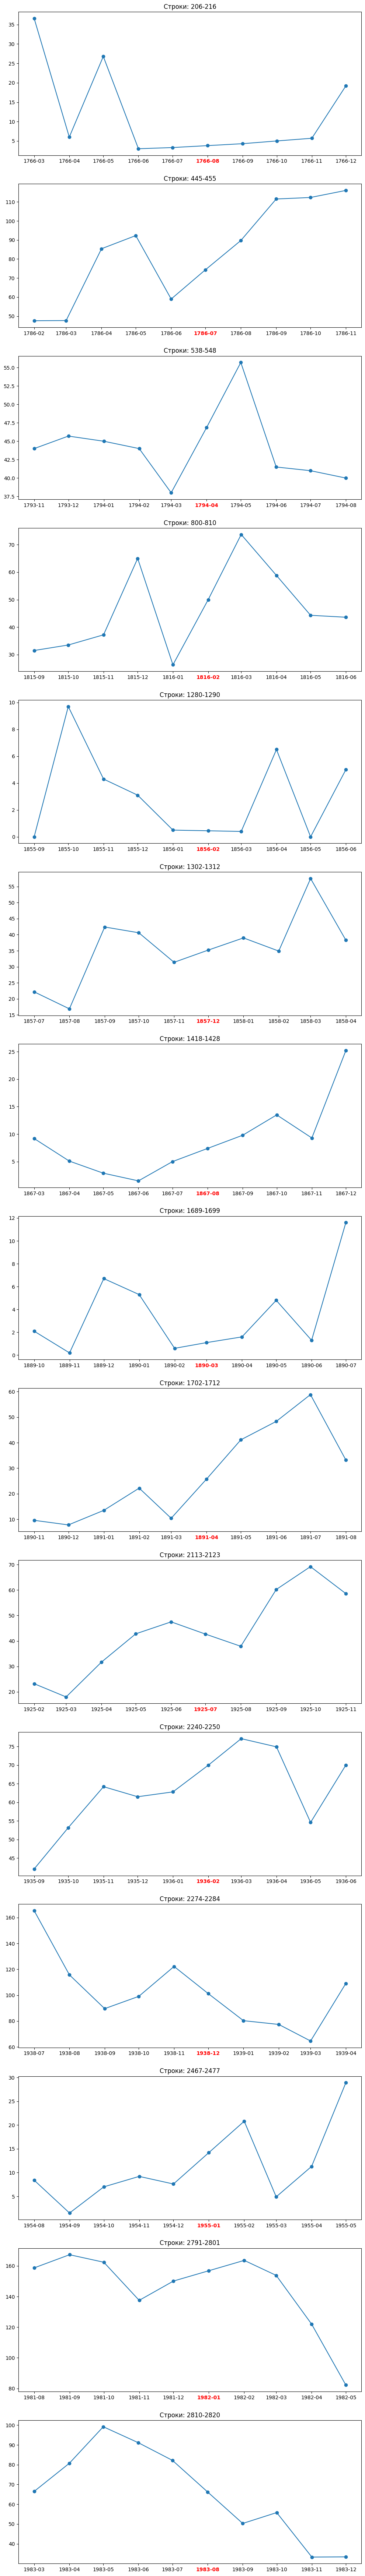

In [29]:
draw_slices(df, 'Month', 'linear', slices)

In [30]:
train['quadratic'] = train['Sunspots'].interpolate(method='quadratic')
test['quadratic'] = test['Sunspots'].interpolate(method='quadratic')
df['quadratic'] = pd.concat([train['quadratic'], test['quadratic']], axis=0)

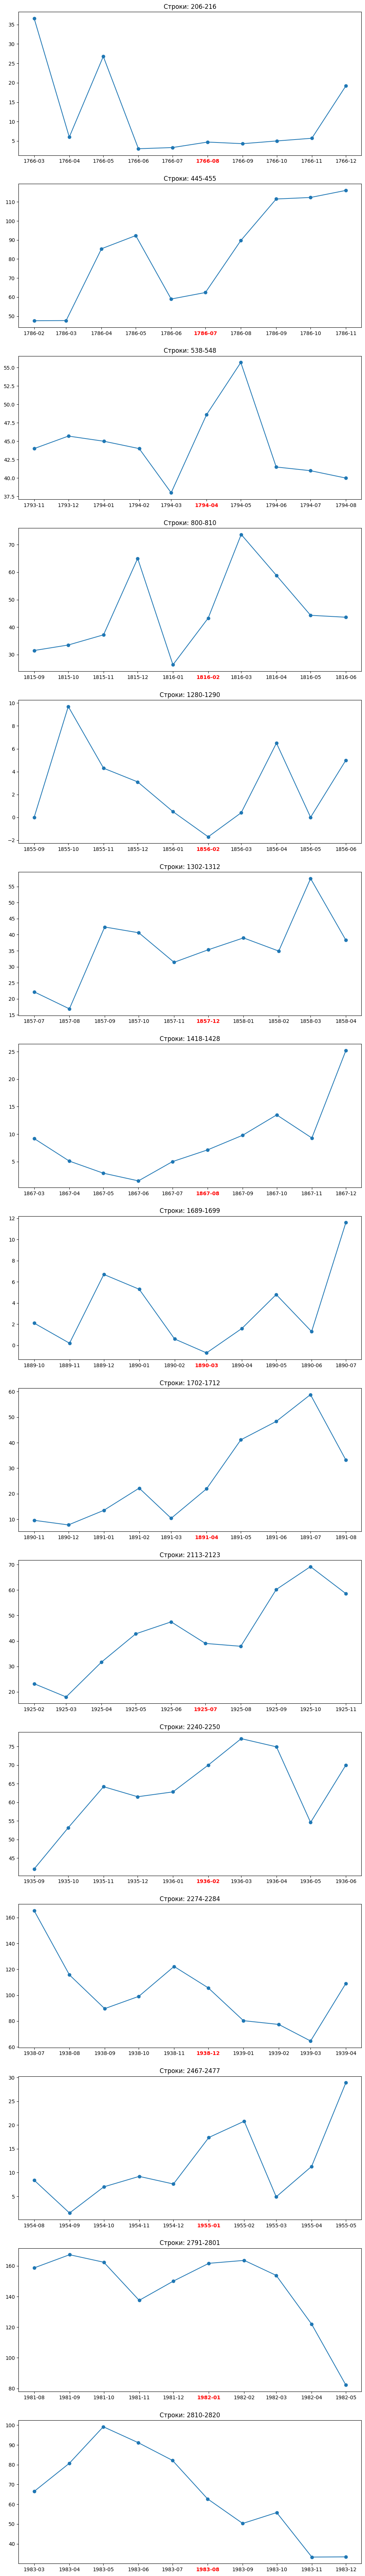

In [31]:
draw_slices(df, 'Month', 'quadratic', slices)

In [32]:
from sklearn.impute import KNNImputer

In [33]:
knn_train = KNNImputer(n_neighbors=5)
train['knn'] = knn_train.fit_transform(train[['Sunspots']])

In [34]:
knn_test = KNNImputer(n_neighbors=5)
test['knn'] = knn_test.fit_transform(test[['Sunspots']])

In [35]:
df['knn'] = pd.concat([train['knn'], test['knn']], axis=0)

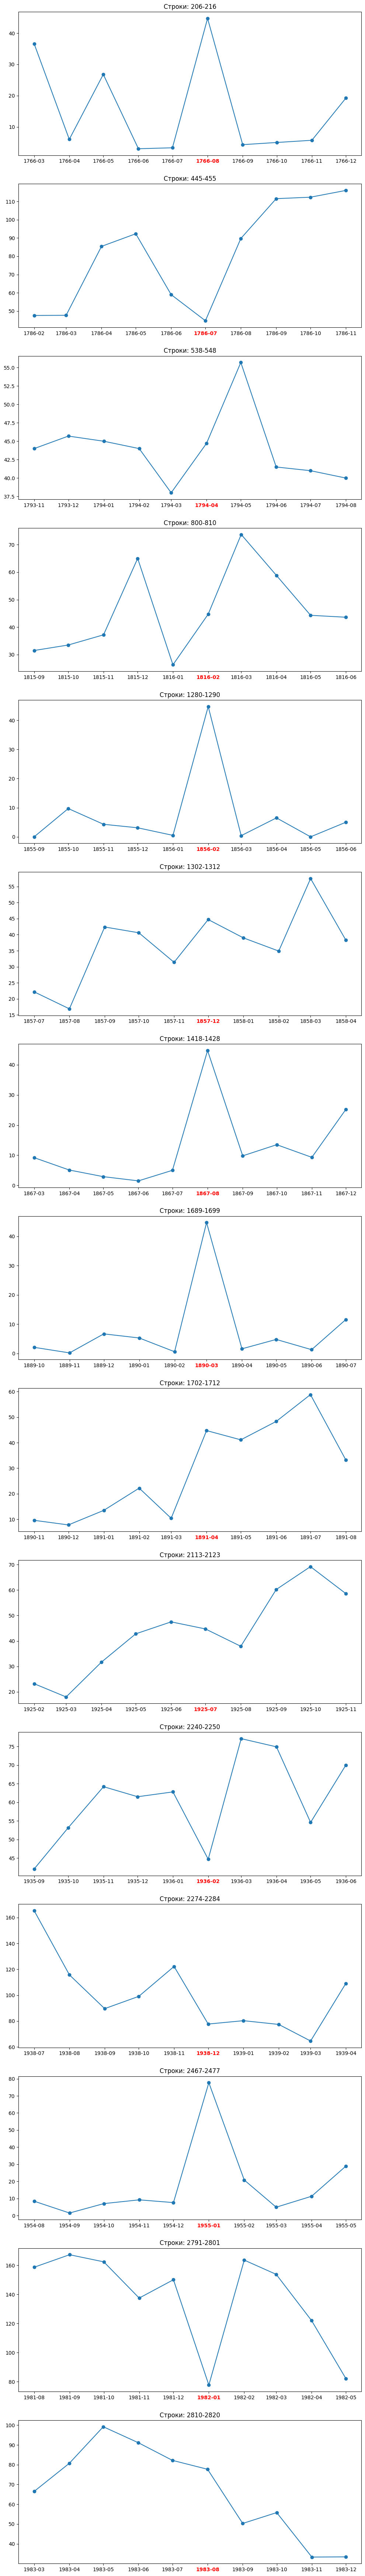

In [36]:
draw_slices(df, 'Month', 'knn', slices)

In [37]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

In [38]:
mice_train = IterativeImputer(max_iter=10)
train['mice'] = mice_train.fit_transform(train[['Sunspots']])

In [39]:
mice_test = IterativeImputer(max_iter=10)
test['mice'] = mice_test.fit_transform(test[['Sunspots']])

In [40]:
df['mice'] = pd.concat([train['mice'], test['mice']], axis=0)

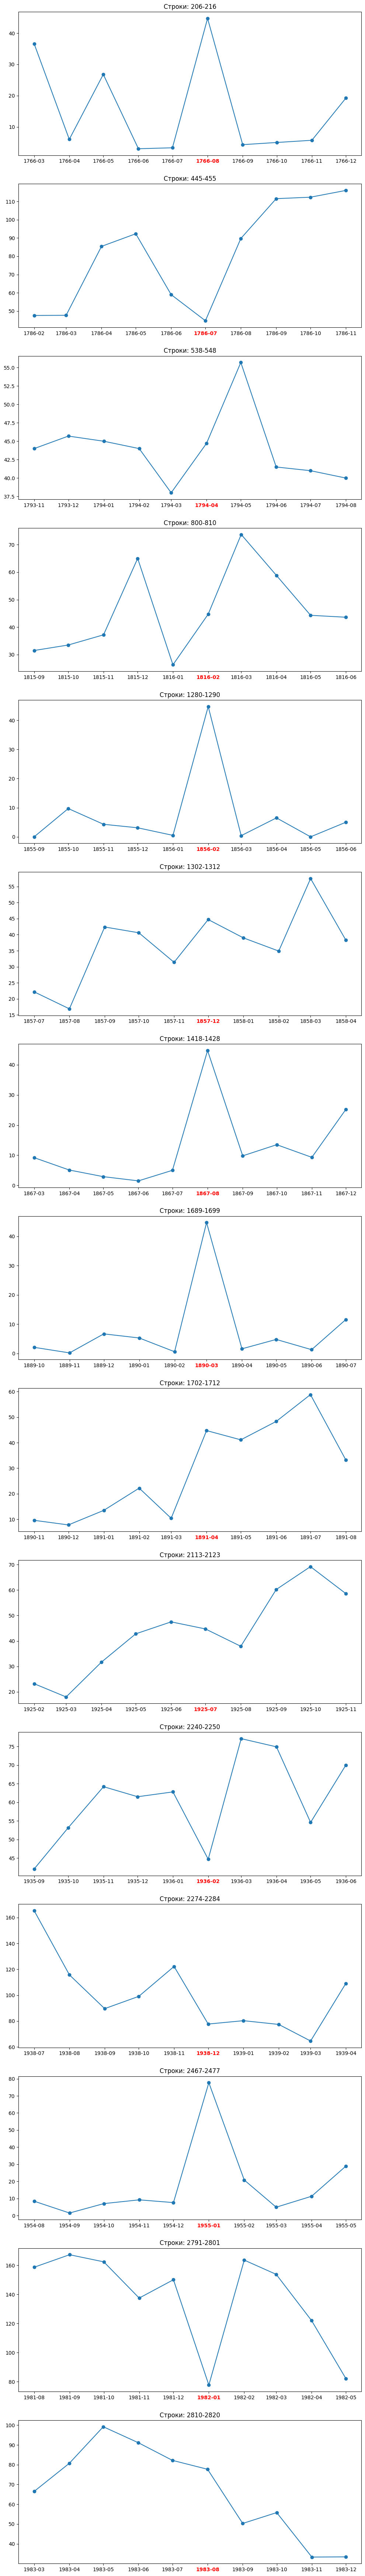

In [41]:
draw_slices(df, 'Month', 'mice', slices)

# Сравнение методов

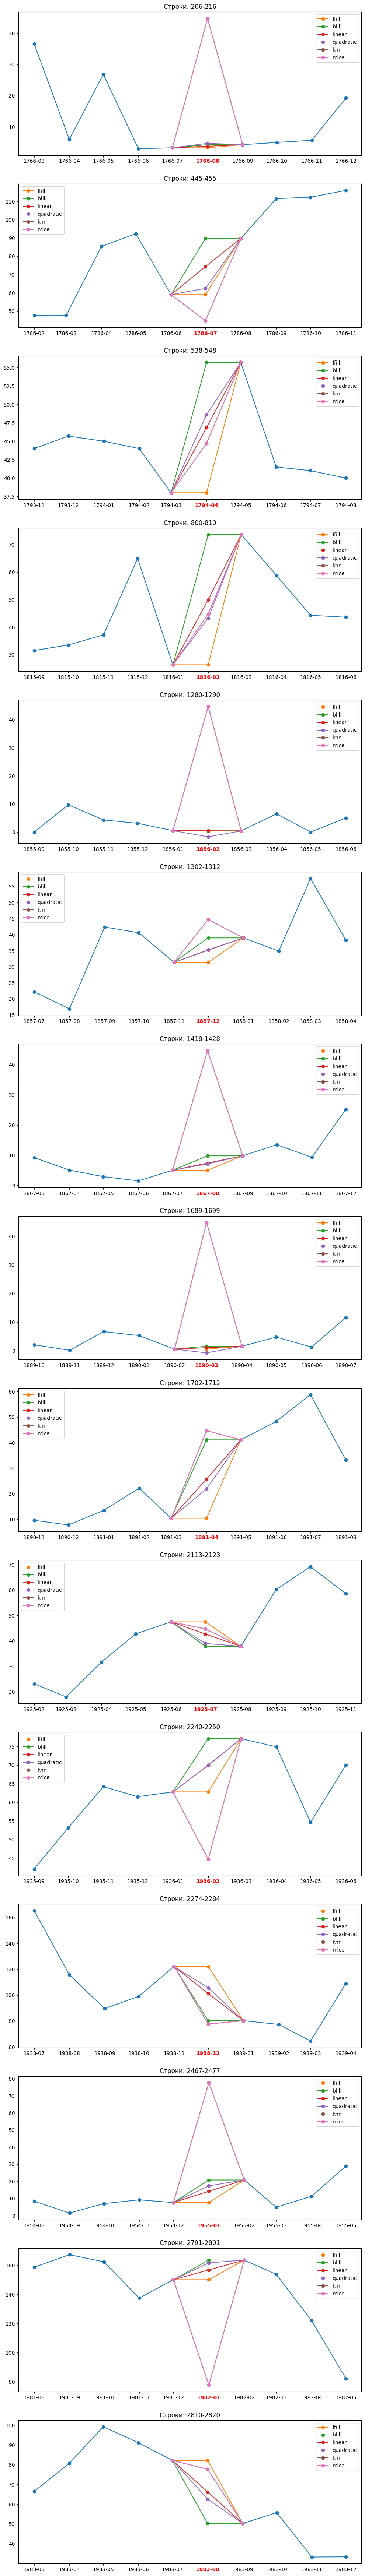

In [42]:
methods = ['ffill', 'bfill', 'linear', 'quadratic', 'knn', 'mice']

n_rows = len(slices)

fig, ax = plt.subplots(n_rows, 1, figsize=(12, 6*n_rows))
if n_rows == 1:
    ax = [ax]

for i in range(n_rows):
    x_slice = df['Month'][slices[i][0]:slices[i][1]].copy()
    y_slice = df['Sunspots'][slices[i][0]:slices[i][1]].copy()
    
    ax[i].plot(x_slice, y_slice, marker='o')
    ax[i].set_title(f'Строки: {slices[i][0]}-{slices[i][1]}')
    
    
    for target_col in methods:
        x = [
            df['Month'][sum(slices[i])/2 - 1],
            df['Month'][sum(slices[i])/2],
            df['Month'][sum(slices[i])/2 + 1]
        ]
        y = [
            df[target_col][sum(slices[i])/2 - 1],
            df[target_col][sum(slices[i])/2],
            df[target_col][sum(slices[i])/2 + 1]
        ]
        ax[i].plot(x, y, label=target_col, marker='o')
        
    ax[i].legend()
    label = ax[i].get_xticklabels()[slice_size]
    label.set_color('red')
    label.set_weight('bold')

# Нахождение выбросов

(array([808., 543., 435., 237., 127.,  65.,  31.,   8.,   1.,   1.]),
 array([  0.  ,  23.89,  47.78,  71.67,  95.56, 119.45, 143.34, 167.23,
        191.12, 215.01, 238.9 ]),
 <BarContainer object of 10 artists>)

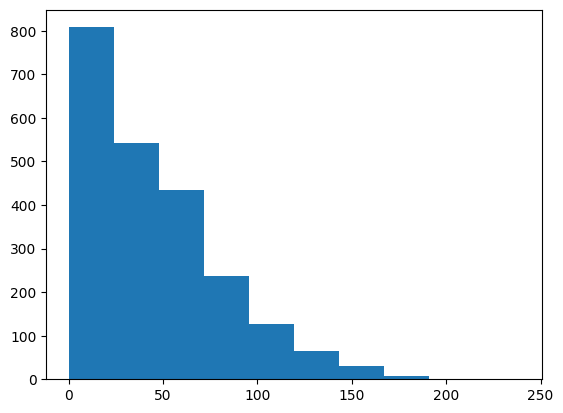

In [43]:
plt.hist(train['linear'])

In [44]:
a = train['linear'].mean()
sigma = train['linear'].std()
bounds = (
    a - 3*sigma,
    a + 3*sigma
)
bounds

(-66.98042378563467, 156.29890782818785)

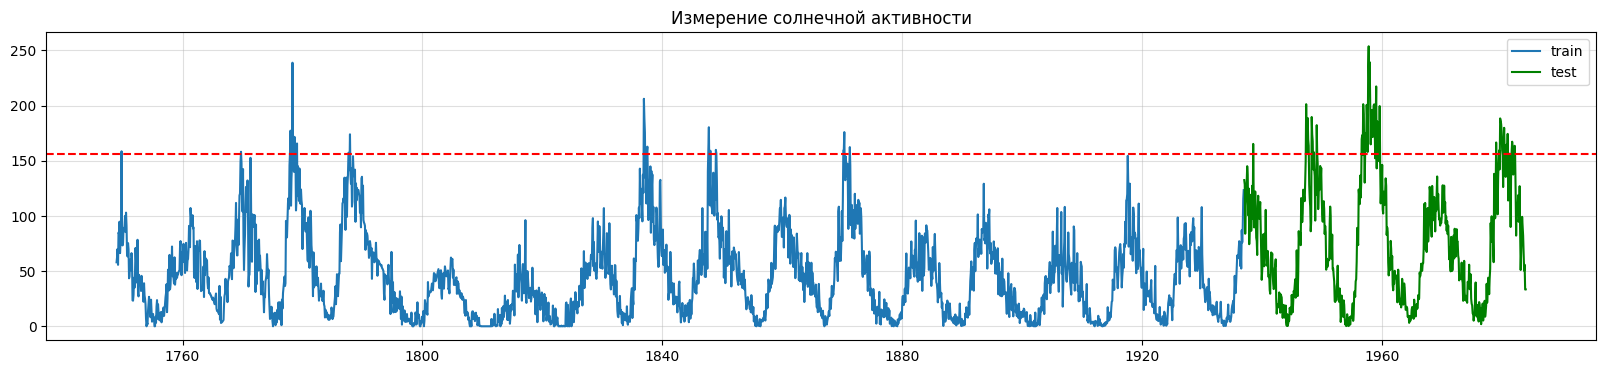

In [45]:
plt.figure(figsize=(20, 4))
plt.plot(train['Month'], train['linear'], label='train')
plt.plot(test['Month'], test['linear'], c='g', label='test')
plt.axhline(y=bounds[1], linestyle='--', c='red')
plt.title('Измерение солнечной активности')
plt.legend()
plt.grid(alpha=0.4)

In [46]:
train['cliped_linear'] = np.clip(train['linear'], bounds[0], bounds[1])

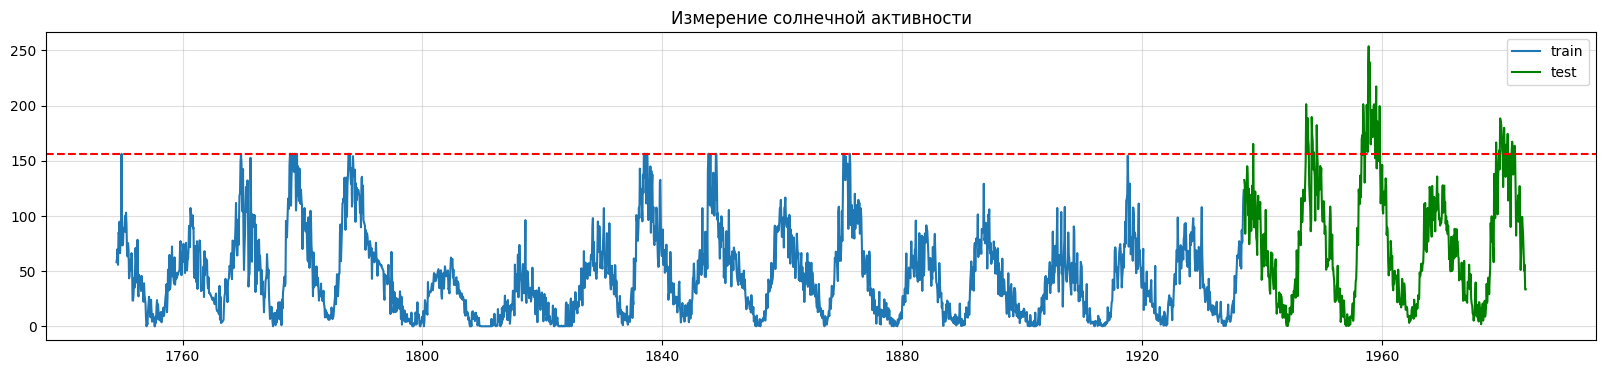

In [47]:
plt.figure(figsize=(20, 4))
plt.plot(train['Month'], train['cliped_linear'], label='train')
plt.plot(test['Month'], test['linear'], c='g', label='test')
plt.axhline(y=bounds[1], linestyle='--', c='red')
plt.title('Измерение солнечной активности')
plt.legend()
plt.grid(alpha=0.4)

In [48]:
train.head()

,Month,Sunspots,ffill,bfill,linear,quadratic,knn,mice,cliped_linear
0,1749-01-01,58.0,58.0,58.0,58.0,58.0,58.0,58.0,58.0
1,1749-02-01,62.6,62.6,62.6,62.6,62.6,62.6,62.6,62.6
2,1749-03-01,70.0,70.0,70.0,70.0,70.0,70.0,70.0,70.0
3,1749-04-01,55.7,55.7,55.7,55.7,55.7,55.7,55.7,55.7
4,1749-05-01,85.0,85.0,85.0,85.0,85.0,85.0,85.0,85.0


# Обучаем наивную модель

In [49]:
from etna.datasets import TSDataset
from etna.models import NaiveModel
from etna.pipeline import Pipeline
from etna.analysis import plot_forecast

C:\Users\Denis\miniconda3\envs\ts\lib\site-packages\etna\settings.py:35: UserWarning: etna[torch] is not available, to install it, run `pip install etna[torch]`
  warnings.warn("etna[torch] is not available, to install it, run `pip install etna[torch]`")
C:\Users\Denis\miniconda3\envs\ts\lib\site-packages\etna\settings.py:49: UserWarning: etna[chronos] is not available, to install it, run `pip install etna[chronos]`
  warnings.warn("etna[chronos] is not available, to install it, run `pip install etna[chronos]`")
C:\Users\Denis\miniconda3\envs\ts\lib\site-packages\etna\settings.py:64: UserWarning: etna[timesfm] is not available, to install it, run `pip install etna[timesfm]`
  warnings.warn("etna[timesfm] is not available, to install it, run `pip install etna[timesfm]`")
C:\Users\Denis\miniconda3\envs\ts\lib\site-packages\etna\settings.py:72: UserWarning: wandb is not available, to install it, run `pip install etna[wandb]`
  warnings.warn("wandb is not available, to install it, run `pip

In [50]:
df_for_etna = pd.concat([train[['Month', 'cliped_linear']].rename(columns={'cliped_linear': 'target'}), test[['Month', 'linear']].rename(columns={'linear': 'target'})])
df_for_etna = df_for_etna.rename(columns={'Month': 'timestamp'})
df_for_etna['segment'] = 0

In [51]:
ts = TSDataset(df_for_etna, freq='MS')

In [57]:
horizont = len(test)

In [58]:
horizon

564

In [59]:
train_ts, test_ts = ts.train_test_split(test_size=horizont)

In [60]:
naive_model = NaiveModel()
naive_pipeline = Pipeline(model=naive_model, horizon=horizont)

In [61]:
naive_pipeline.fit(train_ts)
naive_forecast_ts = naive_pipeline.forecast()

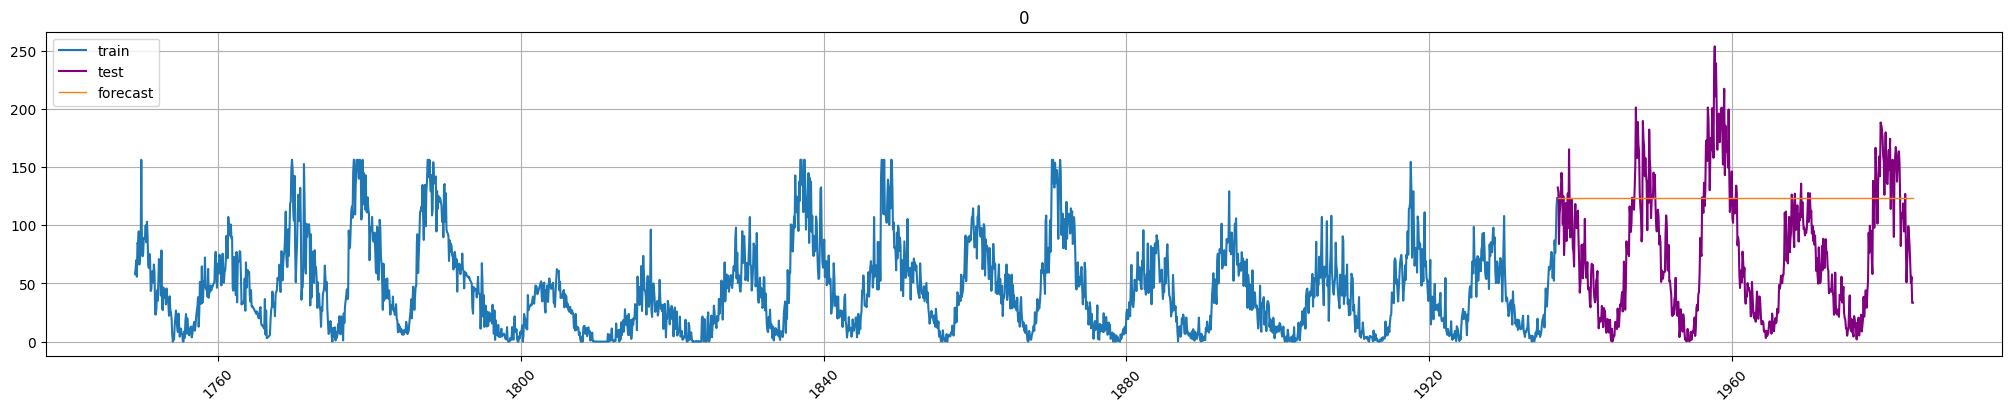

In [62]:
plot_forecast(naive_forecast_ts, test_ts, train_ts, figsize=(20, 4))

In [63]:
from sktime.forecasting.naive import NaiveForecaster

In [64]:
forecaster = NaiveForecaster(strategy="last")

In [65]:
train_sktime_df = train[['Month','cliped_linear']].set_index('Month')

In [66]:
forecaster.fit(train_sktime_df)

NaiveForecaster()

In [67]:
from sktime.forecasting.base import ForecastingHorizon

In [68]:
dates_list = test.set_index('Month')

fh = ForecastingHorizon(
    dates_list.index, 
    is_relative=False
)

In [69]:
y_pred = forecaster.predict(fh).reset_index()

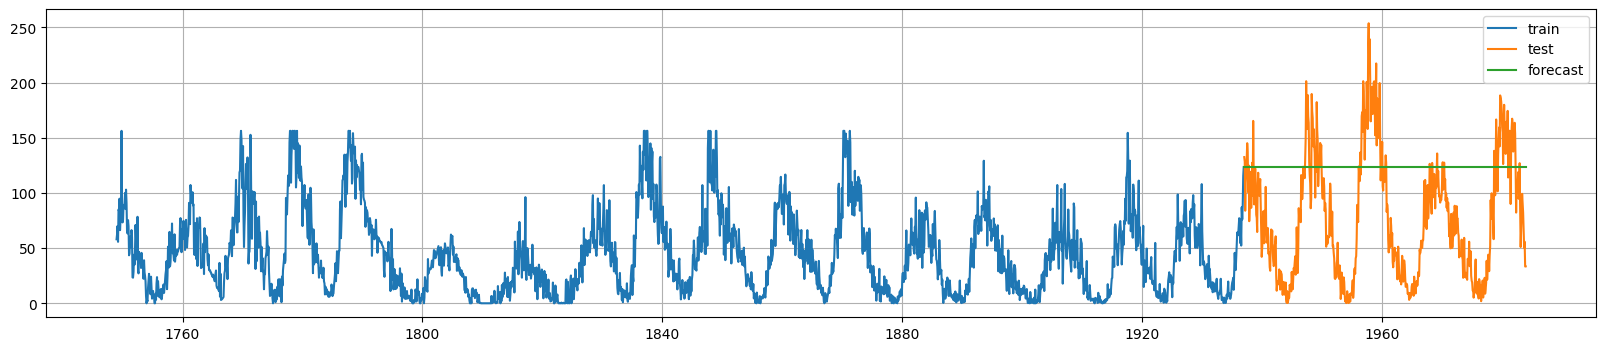

In [70]:
plt.figure(figsize=(20, 4))
plt.plot(train['Month'], train['cliped_linear'], label='train')
plt.plot(test['Month'], test['linear'], label='test')
plt.plot(y_pred['Month'], y_pred['cliped_linear'], label='forecast')
plt.legend()
plt.grid()

In [71]:
proccessed_df = df_for_etna.drop(columns='segment').rename(columns={'timestamp': 'Month', 'target': 'Sunspots'})
train, test = train_test_split(proccessed_df, test_size=0.2)

In [72]:
proccessed_df

,Month,Sunspots
0,1749-01-01,58.00
1,1749-02-01,62.60
2,1749-03-01,70.00
3,1749-04-01,55.70
4,1749-05-01,85.00
...,...,...
2815,1983-08-01,66.25
2816,1983-09-01,50.30
2817,1983-10-01,55.80
2818,1983-11-01,33.30


In [74]:
proccessed_df.to_csv('../data/proccessed_sunspots.csv')